In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset.arff
/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset.xlsx
/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset_Citation_Request.txt


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.io import arff

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Read Dataset
file_path = '/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset.arff'

data, meta = arff.loadarff(file_path)

df = pd.DataFrame(data)

for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].str.decode('utf-8')

print(df.head())
print("Dataset Shape:", df.shape)


      Area  Perimeter  MajorAxisLength  MinorAxisLength  AspectRation  \
0  28395.0    610.291       208.178117       173.888747      1.197191   
1  28734.0    638.018       200.524796       182.734419      1.097356   
2  29380.0    624.110       212.826130       175.931143      1.209713   
3  30008.0    645.884       210.557999       182.516516      1.153638   
4  30140.0    620.134       201.847882       190.279279      1.060798   

   Eccentricity  ConvexArea  EquivDiameter    Extent  Solidity  roundness  \
0      0.549812     28715.0     190.141097  0.763923  0.988856   0.958027   
1      0.411785     29172.0     191.272750  0.783968  0.984986   0.887034   
2      0.562727     29690.0     193.410904  0.778113  0.989559   0.947849   
3      0.498616     30724.0     195.467062  0.782681  0.976696   0.903936   
4      0.333680     30417.0     195.896503  0.773098  0.990893   0.984877   

   Compactness  ShapeFactor1  ShapeFactor2  ShapeFactor3  ShapeFactor4  Class  
0     0.913358    

In [3]:

print("Dataset Shape:", df.shape)

print("\nNumber of Classes:")
print(df['Class'].nunique())

print("\nClass Distribution:")
print(df['Class'].value_counts())

print("\nMissing Values:")
print(df.isnull().sum().sum())


Dataset Shape: (13611, 17)

Number of Classes:
7

Class Distribution:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Missing Values:
0


In [4]:

print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nClass Distribution:")
print(df['Class'].value_counts())

print("\nMissing Values:")
print(df.isnull().sum().sum())


Dataset Shape: (13611, 17)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  float64
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  float64
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class    

In [5]:

X = df.drop('Class', axis=1).values
y = df['Class'].values

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (13611, 16)
Target Shape: (13611,)


In [6]:

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)
print("Encoded Values:", np.unique(y))


Classes: ['BARBUNYA' 'BOMBAY' 'CALI' 'DERMASON' 'HOROZ' 'SEKER' 'SIRA']
Encoded Values: [0 1 2 3 4 5 6]


In [7]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (10888, 16)
X_test: (2723, 16)
y_train: (10888,)
y_test: (2723,)


In [8]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Scaling Completed Successfully!")


Scaling Completed Successfully!


In [9]:

num_classes = len(np.unique(y_train))

Y_train = np.eye(num_classes)[y_train]

print("Number of Classes:", num_classes)
print("Y_train Shape:", Y_train.shape)
print(Y_train[:5])


Number of Classes: 7
Y_train Shape: (10888, 7)
[[0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0.]]


In [10]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n_samples, n_features = X_train.shape

W = np.random.randn(n_features, num_classes) * 0.01
b = np.zeros((1, num_classes))

print("Weights Shape:", W.shape)
print("Bias Shape:", b.shape)


Weights Shape: (16, 7)
Bias Shape: (1, 7)


In [11]:

def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)


In [12]:

def compute_loss(Y_true, Y_pred):
    epsilon = 1e-15
    Y_pred = np.clip(Y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        np.sum(Y_true * np.log(Y_pred), axis=1)
    )

    return loss


In [13]:

learning_rate = 0.05
epochs = 1000
beta = 0.9

vW = np.zeros_like(W)
vb = np.zeros_like(b)

loss_history = []

for epoch in range(epochs):

    # Forward Propagation
    z = np.dot(X_train, W) + b
    y_pred = softmax(z)

    # Calculate Loss
    loss = compute_loss(Y_train, y_pred)
    loss_history.append(loss)

    # Calculate Gradient
    error = y_pred - Y_train

    dW = np.dot(X_train.T, error) / n_samples
    db = np.sum(error, axis=0, keepdims=True) / n_samples

    # Momentum
    vW = beta * vW + dW
    vb = beta * vb + db

    # Update Parameters
    W -= learning_rate * vW
    b -= learning_rate * vb

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss:.4f}")

print("Training Completed!")


Epoch 100, Loss: 0.2949
Epoch 200, Loss: 0.2576
Epoch 300, Loss: 0.2431
Epoch 400, Loss: 0.2353
Epoch 500, Loss: 0.2304
Epoch 600, Loss: 0.2270
Epoch 700, Loss: 0.2245
Epoch 800, Loss: 0.2227
Epoch 900, Loss: 0.2212
Epoch 1000, Loss: 0.2201
Training Completed!


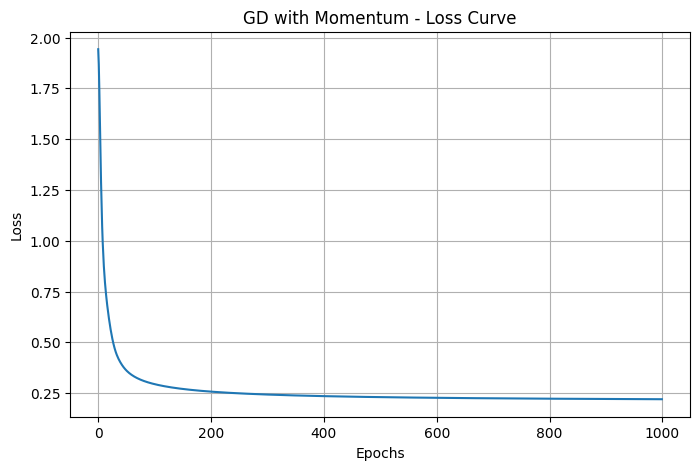

In [14]:

plt.figure(figsize=(8, 5))
plt.plot(loss_history)

plt.title("GD with Momentum - Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.grid()
plt.show()


In [15]:

z_test = np.dot(X_test, W) + b

y_test_prob = softmax(z_test)

y_pred = np.argmax(y_test_prob, axis=1)

print("Predictions:", y_pred[:10])
print("Actual:", y_test[:10])


Predictions: [3 1 6 5 0 5 3 6 2 4]
Actual: [3 1 6 5 0 5 3 6 0 4]


In [16]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average='macro'
)

recall = recall_score(
    y_test, y_pred, average='macro'
)

f1 = f1_score(
    y_test, y_pred, average='macro'
)

print("GD with Momentum Results")
print("-------------------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)


GD with Momentum Results
-------------------------
Accuracy: 0.9203084832904884
Precision: 0.9339589271843772
Recall: 0.9302893213400724
F1 Score: 0.9318911550876253


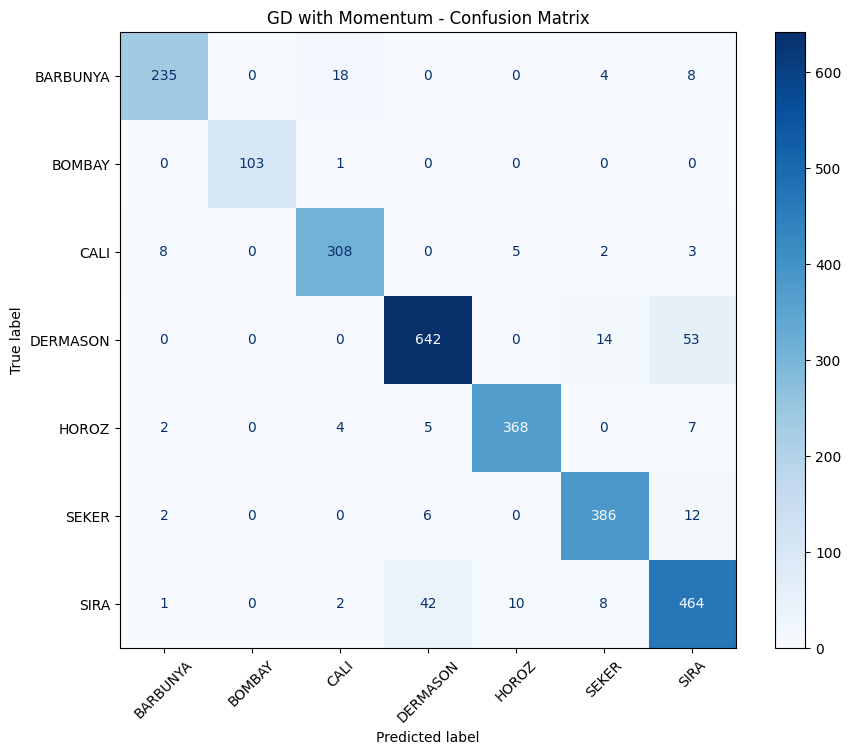

In [17]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)

plt.title("GD with Momentum - Confusion Matrix")
plt.show()


In [18]:

gd_results = {
    'Optimizer': 'GD with Momentum',
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1 Score': f1,
    'Loss': loss_history[-1]
}

results_df = pd.DataFrame([gd_results])

print(results_df)


          Optimizer  Accuracy  Precision    Recall  F1 Score     Loss
0  GD with Momentum  0.920308   0.933959  0.930289  0.931891  0.22007
